# 01 — Exploración de datos (RepoRT C18)

Se describe la instantánea fija de la OBT del PSet 2. La unidad de análisis es una observación de retención; para evitar que mediciones repetidas de un compuesto contaminen la validación, los modelos posteriores separan por InChIKey.

In [1]:
from pathlib import Path
import os
import sys

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from src.datos import load_snapshot
from src.pipeline import (
    FEATURE_COLUMNS,
    RAW_FEATURE_COLUMNS,
    MoleculeConditionFeatures,
    valid_smiles_mask,
)
from src.splits import create_or_load_holdout

sns.set_theme(style="whitegrid")
frame, snapshot_metadata = load_snapshot()
valid_mask = valid_smiles_mask(frame)
all_data = frame.loc[valid_mask & frame["inchikey"].notna()].reset_index(drop=True)
data, holdout_data, split_metadata = create_or_load_holdout(
    all_data, source_sha256=snapshot_metadata["sha256"]
)
print(f"Filas C18: {len(frame):,}; SMILES válidos: {valid_mask.sum():,}; compuestos: {all_data['inchikey'].nunique():,}")
print(f"EDA/desarrollo: {len(data):,} filas; holdout reservado sin inspección: {len(holdout_data):,} filas")
print(f"SHA-256 de la instantánea: {snapshot_metadata['sha256']}")

Filas C18: 152,586; SMILES válidos: 152,586; compuestos: 96,482
EDA/desarrollo: 122,370 filas; holdout reservado sin inspección: 30,216 filas
SHA-256 de la instantánea: 0c366b465f7b56e6b5873132279f7a3152532f0a035186c776f491c01a628210


(122370, 8)

,dtype,faltantes,faltantes_%
hecho_id,string,0,0.00
inchikey,string,0,0.00
nombre_compuesto,object,65327,53.38
tipo_columna,object,0,0.00
fase_movil,object,0,0.00
flujo_ml_min,float64,5323,4.35
tiempo_retencion,float64,0,0.00
smiles,object,0,0.00


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
hecho_id,122370,122370,9a8b11e00e659c1a52903d434473870e,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
inchikey,122370,77185,WQZGKKKJIJFFOK-UHFFFAOYSA-N,211,NaN,NaN,NaN,NaN,NaN,NaN,NaN
nombre_compuesto,57043,11984,ALLOSE,211,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tipo_columna,122370,28,Agilent ZORBAX Extend-C18,64297,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fase_movil,122370,12,A[H2O=100; MeOH=0; ACN=0] B[H2O=0; MeOH=0; ACN...,102914,NaN,NaN,NaN,NaN,NaN,NaN,NaN
flujo_ml_min,117047.0,NaN,NaN,NaN,0.23494,0.176184,0.04,0.1,0.1,0.4,1.0
tiempo_retencion,122370.0,NaN,NaN,NaN,9.289154,5.679083,0.005,3.862075,10.341667,13.575,49.97
smiles,122370,77185,C(C1C(C(C(C(O1)O)O)O)O)O,211,NaN,NaN,NaN,NaN,NaN,NaN,NaN


{'mediana_min': 10.341666666666669, 'q1_min': 3.862075, 'q3_min': 13.575, 'IQR_min': 9.712924999999998, 'outliers_IQR': 94, 'outliers_Z3': 149}


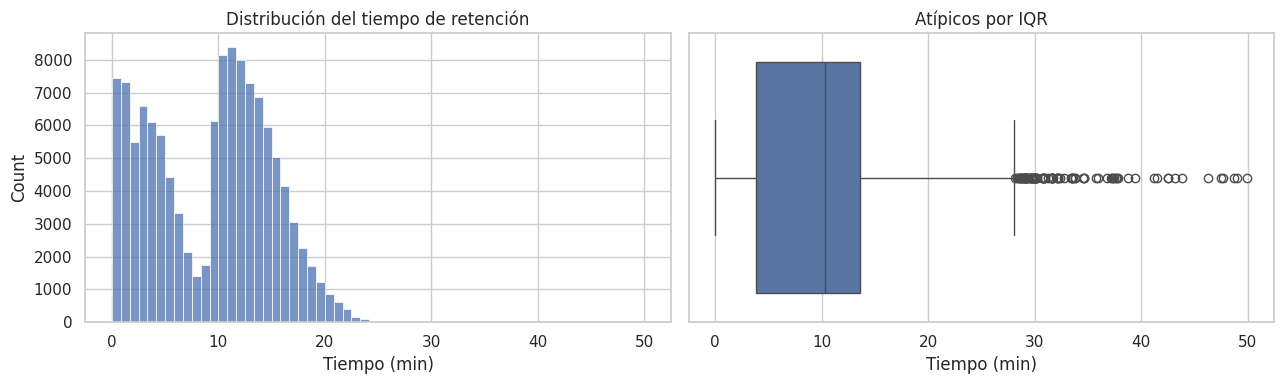

In [2]:
display(data.shape)
display(pd.DataFrame({"dtype": data.dtypes.astype(str), "faltantes": data.isna().sum(), "faltantes_%": (100 * data.isna().mean()).round(2)}))
display(data.describe(include="all").T)

target = data["tiempo_retencion"].astype(float)
q1, q3 = target.quantile([0.25, 0.75])
iqr = q3 - q1
iqr_outliers = (target < q1 - 1.5 * iqr) | (target > q3 + 1.5 * iqr)
z_scores = (target - target.mean()) / target.std(ddof=0)
z_outliers = z_scores.abs() >= 3
print({"mediana_min": target.median(), "q1_min": q1, "q3_min": q3, "IQR_min": iqr, "outliers_IQR": int(iqr_outliers.sum()), "outliers_Z3": int(z_outliers.sum())})

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(target, bins=60, ax=axes[0])
axes[0].set(title="Distribución del tiempo de retención", xlabel="Tiempo (min)")
sns.boxplot(x=target, ax=axes[1])
axes[1].set(title="Atípicos por IQR", xlabel="Tiempo (min)")
plt.tight_layout()
plt.show()

## Forma de la distribución del target

Además de la mediana y el IQR se cuantifican asimetría, curtosis y colas. Los atípicos del target se marcan con dos criterios: IQR (1,5 × IQR, diagrama de caja) y |Z| ≥ 3.

,valor
n,122370.000
media_min,9.289
mediana_min,10.342
desv_est_min,5.679
asimetria,0.084
curtosis_exceso,-0.747
p01_min,0.554
p99_min,21.181
max_min,49.970
pct_menor_1_min,7.435


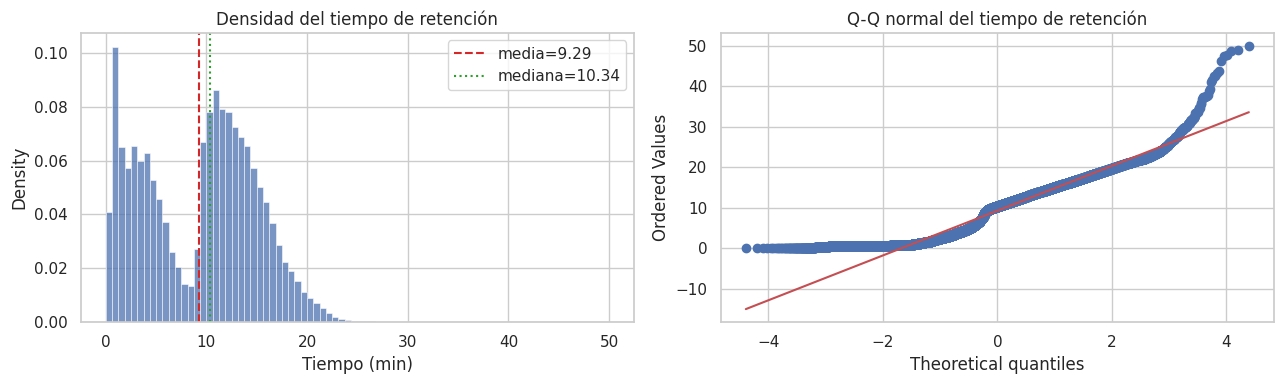

In [3]:
from scipy import stats

target_profile = pd.Series({
    "n": len(target),
    "media_min": target.mean(),
    "mediana_min": target.median(),
    "desv_est_min": target.std(),
    "asimetria": stats.skew(target),
    "curtosis_exceso": stats.kurtosis(target),
    "p01_min": target.quantile(0.01),
    "p99_min": target.quantile(0.99),
    "max_min": target.max(),
    "pct_menor_1_min": 100 * (target < 1).mean(),
    "pct_mayor_30_min": 100 * (target > 30).mean(),
    "pct_atipicos_IQR": 100 * iqr_outliers.mean(),
    "pct_atipicos_Z3": 100 * z_outliers.mean(),
})
display(target_profile.round(3).to_frame("valor"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(target, bins=80, stat="density", ax=axes[0])
axes[0].axvline(target.mean(), color="tab:red", ls="--", label=f"media={target.mean():.2f}")
axes[0].axvline(target.median(), color="tab:green", ls=":", label=f"mediana={target.median():.2f}")
axes[0].legend()
axes[0].set(title="Densidad del tiempo de retención", xlabel="Tiempo (min)")
stats.probplot(target, dist="norm", plot=axes[1])
axes[1].set_title("Q-Q normal del tiempo de retención")
plt.tight_layout()
plt.show()

**Desbalance de clases:** no aplica. El problema es de regresión (minutos de retención). El equivalente de este análisis es la cobertura del rango del target; por ello la muestra de desarrollo de `02_features` se estratifica por quintiles de la retención mediana de cada compuesto.

,spearman_con_tiempo
flow_ml_min,-0.717100
mol_logp,0.575429
mol_aromatic_rings,0.530324
mol_h_donors,-0.478536
mol_ring_count,0.444067
mol_weight,0.398240
mol_fraction_csp3,-0.281040
mol_tpsa,-0.167034
mol_rotatable_bonds,0.166670
elu_b_acn,0.165630


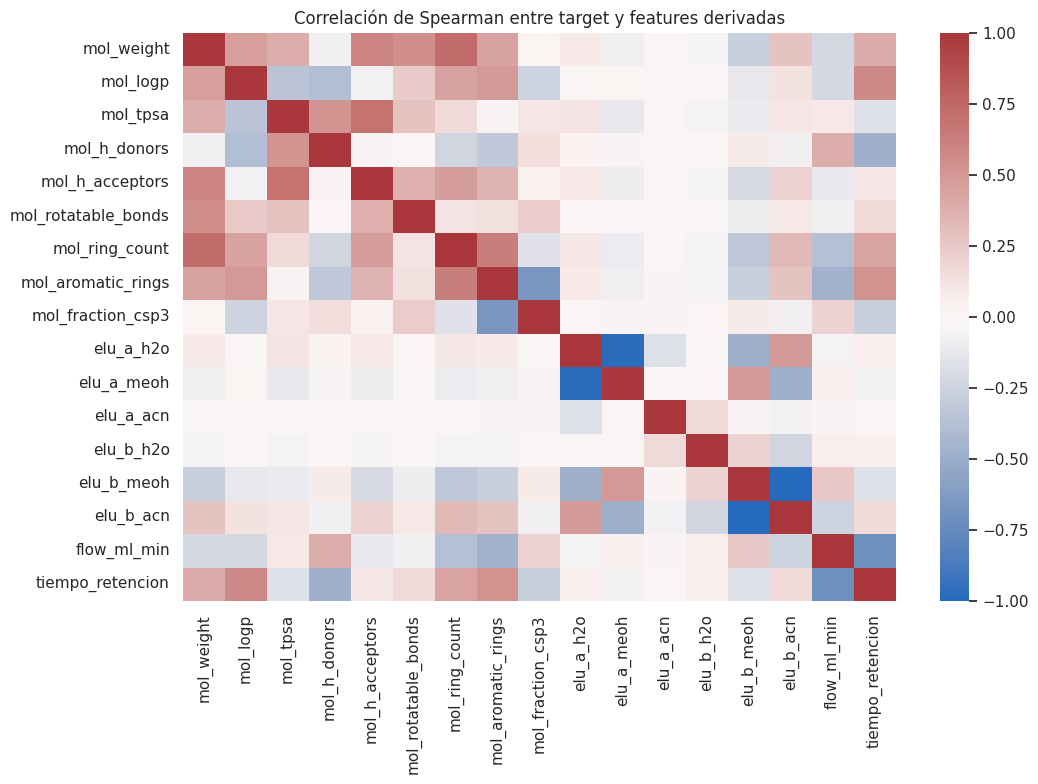

In [4]:
raw_features = data.loc[:, RAW_FEATURE_COLUMNS]
derived = MoleculeConditionFeatures().fit_transform(raw_features)
eda_numeric = derived.assign(tiempo_retencion=target.to_numpy())
correlations = eda_numeric.corr(method="spearman")["tiempo_retencion"].drop("tiempo_retencion").dropna()
display(correlations.reindex(correlations.abs().sort_values(ascending=False).index).to_frame("spearman_con_tiempo"))
plt.figure(figsize=(11, 8))
sns.heatmap(eda_numeric.corr(method="spearman"), cmap="vlag", center=0, vmin=-1, vmax=1)
plt.title("Correlación de Spearman entre target y features derivadas")
plt.tight_layout()
plt.show()

## Atípicos en las features (IQR y Z-score)

Se aplica el mismo doble criterio a las features derivadas. Las variables se estandarizan solo para dibujar los diagramas de caja en una escala común.

,faltantes_%,asimetria,atipicos_IQR_%,atipicos_Z3_%
feature,,,,
elu_b_acn,0.00,-1.92,15.58,0.00
elu_b_meoh,0.30,1.92,15.37,0.00
mol_h_donors,0.00,2.68,10.08,2.27
mol_tpsa,0.00,2.88,6.52,1.90
mol_logp,0.00,-0.83,4.31,0.90
elu_a_h2o,0.00,-13.42,4.31,4.31
elu_a_meoh,0.00,4.70,4.17,4.17
mol_rotatable_bonds,0.00,2.33,3.47,1.92
mol_h_acceptors,0.00,2.22,3.20,1.52


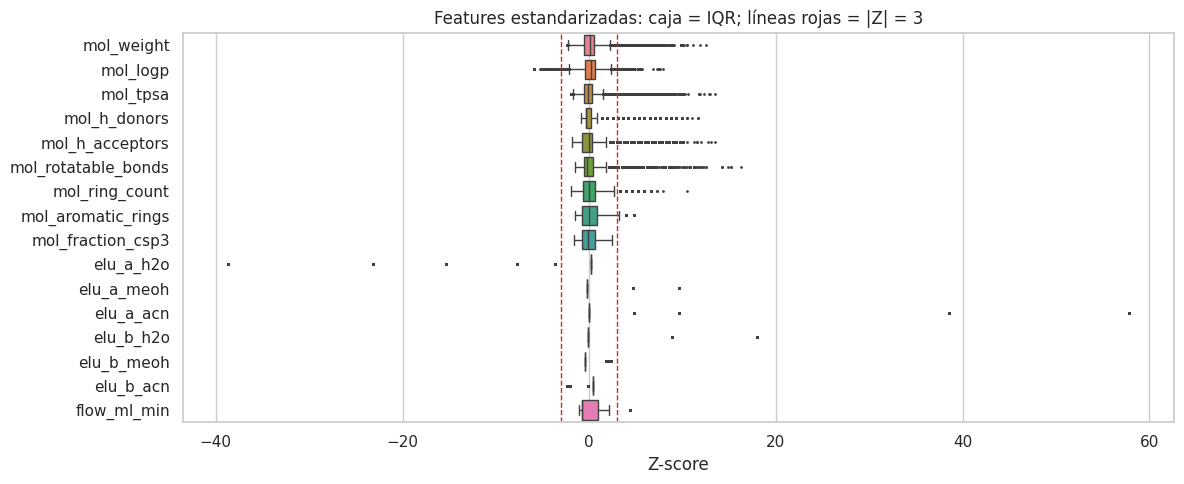

In [5]:
def outlier_summary(frame):
    rows = []
    for column in frame.columns:
        values = frame[column].dropna().astype(float)
        q_low, q_high = values.quantile([0.25, 0.75])
        spread = q_high - q_low
        iqr_flag = (values < q_low - 1.5 * spread) | (values > q_high + 1.5 * spread)
        std = values.std(ddof=0)
        z_flag = ((values - values.mean()) / std).abs() >= 3 if std > 0 else values.lt(values.min())
        rows.append({
            "feature": column,
            "faltantes_%": 100 * frame[column].isna().mean(),
            "asimetria": stats.skew(values) if std > 0 else 0.0,
            "atipicos_IQR_%": 100 * iqr_flag.mean(),
            "atipicos_Z3_%": 100 * z_flag.mean(),
        })
    return pd.DataFrame(rows).set_index("feature").sort_values("atipicos_IQR_%", ascending=False)

feature_outlier_table = outlier_summary(derived)
display(feature_outlier_table.round(2))

standardized = (derived - derived.mean()) / derived.std(ddof=0).replace(0, np.nan)
plt.figure(figsize=(12, 5))
sns.boxplot(data=standardized.dropna(axis=1, how="all"), orient="h", fliersize=1)
plt.axvline(3, color="tab:red", ls="--", lw=1)
plt.axvline(-3, color="tab:red", ls="--", lw=1)
plt.title("Features estandarizadas: caja = IQR; líneas rojas = |Z| = 3")
plt.xlabel("Z-score")
plt.tight_layout()
plt.show()

## ¿Pearson o Spearman?

Se usa **Spearman** como medida principal porque: (1) varias features son muy asimétricas y tienen atípicos (TPSA ≈ 2,9; donadores de H ≈ 2,7; fracciones de la fase B ≈ ±1,9 en la tabla anterior), y Pearson es sensible a valores extremos; (2) el target no es normal: es bimodal y achatado (Q-Q y curtosis −0,75); (3) muchas features son conteos discretos con empates (donadores, anillos, enlaces rotables); (4) en fase reversa la relación esperada entre hidrofobicidad y retención es monotónica, no necesariamente lineal. La tabla siguiente compara ambos coeficientes: coinciden en las asociaciones fuertes (flujo, LogP, anillos aromáticos), pero difieren hasta ≈0,09 en peso molecular, TPSA, enlaces rotables y aceptores de H, donde la relación es monotónica pero no lineal.

In [6]:
pearson = eda_numeric.corr(method="pearson")["tiempo_retencion"].drop("tiempo_retencion")
correlation_comparison = pd.DataFrame({"pearson": pearson, "spearman": correlations}).dropna()
correlation_comparison["spearman_menos_pearson"] = correlation_comparison["spearman"] - correlation_comparison["pearson"]
display(correlation_comparison.reindex(correlation_comparison["spearman"].abs().sort_values(ascending=False).index).round(3))

,pearson,spearman,spearman_menos_pearson
flow_ml_min,-0.699,-0.717,-0.018
mol_logp,0.568,0.575,0.007
mol_aromatic_rings,0.516,0.530,0.014
mol_h_donors,-0.456,-0.479,-0.022
mol_ring_count,0.418,0.444,0.026
mol_weight,0.313,0.398,0.085
mol_fraction_csp3,-0.284,-0.281,0.003
mol_tpsa,-0.254,-0.167,0.087
mol_rotatable_bonds,0.090,0.167,0.077
elu_b_acn,0.158,0.166,0.007


In [7]:
top_feature = correlations.abs().idxmax()
condition_count = data.groupby(["tipo_columna", "fase_movil", "flujo_ml_min"], dropna=False).ngroups
repeats = data.groupby("inchikey").size()
flow_missing = 100 * data["flujo_ml_min"].isna().mean()
skewed = feature_outlier_table.loc[feature_outlier_table["atipicos_IQR_%"] > 1].index.tolist()
findings = pd.DataFrame([
    {
        "Hallazgo": "1. Target acotado, bimodal y sin cola larga.",
        "Evidencia": (f"asimetría={stats.skew(target):.2f}; curtosis={stats.kurtosis(target):.2f}; modas en 2–6 y 10–16 min; "
                      f"{100 * (target < 1).mean():.1f}% < 1 min; p99={target.quantile(0.99):.1f} min; "
                      f"solo {int(iqr_outliers.sum()):,} atípicos IQR y {int(z_outliers.sum()):,} con |Z|≥3."),
        "Consecuencia en el modelo": ("Sin cola larga no hace falta cambiar RMSE por MAE: RMSE sigue como métrica técnica (penaliza los errores grandes, los costosos) "
                                      "y MAE como complementaria. log(1+target) se prueba en 02 y se descarta si no mejora. No se eliminan atípicos. "
                                      "La bimodalidad sugiere métodos de distinta duración: refuerza el hallazgo 3."),
    },
    {
        "Hallazgo": "2. Mediciones repetidas del mismo compuesto.",
        "Evidencia": f"{len(data):,} filas para {data['inchikey'].nunique():,} InChIKey; hasta {repeats.max()} mediciones por compuesto.",
        "Consecuencia en el modelo": "Holdout y CV agrupados por InChIKey (GroupKFold): un compuesto nunca aparece en entrenamiento y validación a la vez.",
    },
    {
        "Hallazgo": "3. Las condiciones del método explican gran parte de la retención.",
        "Evidencia": f"{condition_count} condiciones; mayor |Spearman|: {top_feature} (rho={correlations[top_feature]:.3f}).",
        "Consecuencia en el modelo": ("Se derivan fracciones de solvente desde `fase_movil` y se conserva el flujo; "
                                      "la línea base de negocio es la mediana histórica por condición."),
    },
    {
        "Hallazgo": "4. Faltantes concentrados en flujo y nombre.",
        "Evidencia": f"flujo_ml_min: {flow_missing:.2f}% faltante; nombre_compuesto: {100 * data['nombre_compuesto'].isna().mean():.1f}% faltante.",
        "Consecuencia en el modelo": "Imputación por mediana dentro del Pipeline (ajustada por pliegue); el nombre no se usa como predictor.",
    },
    {
        "Hallazgo": "5. Descriptores moleculares con escalas distintas y colas.",
        "Evidencia": f"features con >1% de atípicos IQR: {', '.join(skewed) if skewed else 'ninguna'}.",
        "Consecuencia en el modelo": "StandardScaler en el Pipeline para Ridge/MLP/KNN; los árboles se incluyen por ser robustos a escalas y colas.",
    },
])
with pd.option_context("display.max_colwidth", None):
    display(findings)
print("No se eliminan atípicos automáticamente: se conservan salvo evidencia de error de captura.")

,Hallazgo,Evidencia,Consecuencia en el modelo
0,"1. Target acotado, bimodal y sin cola larga.",asimetría=0.08; curtosis=-0.75; modas en 2–6 y 10–16 min; 7.4% < 1 min; p99=21.2 min; solo 94 atípicos IQR y 149 con |Z|≥3.,"Sin cola larga no hace falta cambiar RMSE por MAE: RMSE sigue como métrica técnica (penaliza los errores grandes, los costosos) y MAE como complementaria. log(1+target) se prueba en 02 y se descarta si no mejora. No se eliminan atípicos. La bimodalidad sugiere métodos de distinta duración: refuerza el hallazgo 3."
1,2. Mediciones repetidas del mismo compuesto.,"122,370 filas para 77,185 InChIKey; hasta 211 mediciones por compuesto.",Holdout y CV agrupados por InChIKey (GroupKFold): un compuesto nunca aparece en entrenamiento y validación a la vez.
2,3. Las condiciones del método explican gran parte de la retención.,75 condiciones; mayor |Spearman|: flow_ml_min (rho=-0.717).,Se derivan fracciones de solvente desde `fase_movil` y se conserva el flujo; la línea base de negocio es la mediana histórica por condición.
3,4. Faltantes concentrados en flujo y nombre.,flujo_ml_min: 4.35% faltante; nombre_compuesto: 53.4% faltante.,Imputación por mediana dentro del Pipeline (ajustada por pliegue); el nombre no se usa como predictor.
4,5. Descriptores moleculares con escalas distintas y colas.,"features con >1% de atípicos IQR: elu_b_acn, elu_b_meoh, mol_h_donors, mol_tpsa, mol_logp, elu_a_h2o, elu_a_meoh, mol_rotatable_bonds, mol_h_acceptors, mol_weight, elu_b_h2o.",StandardScaler en el Pipeline para Ridge/MLP/KNN; los árboles se incluyen por ser robustos a escalas y colas.


No se eliminan atípicos automáticamente: se conservan salvo evidencia de error de captura.
